# Inflation: recalibrating Dynamic BPS vs the LDF pool

In [1]:
%load_ext autoreload
%autoreload 2

import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from ldf import ldf_func
from pit import pit_func
from uniformity_tests import uniformity_test
from recal_dma_new import (tvgas_pit_dma_new, convolution_recal_pit_dma_new, dm_test, _hac_lag,
                           _pit_quantiles, _IVL_PROBS, _UN)
from recal_beta_dma_new import tvgas_pit_beta_dma_new, convolution_recal_pit_beta_dma_new
from localised_metrics import evaluate_localized, static_reports
import sim_report as sr
import bps

OUT = Path("figures/inflation"); OUT.mkdir(parents=True, exist_ok=True)

In [2]:
sns.set_style("whitegrid")
sns.set_context("paper")

## 0. Settings

In [3]:
# ---- BPS (MATLAB driver settings) -----------------------------------------------------
BPS_DELTA   = (0.95, 0.99)     # [state discount, obs. variance discount], as `delta` in the MATLAB
BPS_START   = 50               # MATLAB `for t=50:T-1`: first forecast is of period 50 (0-based)
BURN_IN     = 3000
MCMC_ITER   = 8000
EXACT_PORT  = True             # True = reproduce the MATLAB exactly (see bps.py docstring)
N_JOBS      = 4                # forecast origins run in parallel; -1 = all cores
BPS_PATH    = f"results/bps_inflation_{BURN_IN}_{MCMC_ITER}.pkl"   # cache: delete to rerun
# quick test first: set BURN_IN, MCMC_ITER = 300, 500 (about 10x faster)

# ---- LDF comparison --------------------------------------------------------------------
LDF_DELTA   = 0.9

# ---- recalibration (as in inflation.ipynb) ---------------------------------------------
warmup, eval_start, ALPHA = 0, 0, 0.95
STATIC_REFIT = 10              # refit cadence of the static maps (= the network's refit_every)
K_RQS = 4

## 1. Data (as in `inflation.ipynb`)

In [4]:
y = pd.read_excel("data/data.xlsx", sheet_name="Inflation")["Inflation"]
y_t = pd.read_excel("data/data.xlsx", sheet_name="Inflation")
y_t.rename(columns={"Unnamed: 0": "Date"}, inplace=True)
y_t["Date"] = pd.PeriodIndex(y_t["Date"], freq="Q").to_timestamp()

models = ["M1", "M2", "M3", "M4"]
mean = pd.read_excel("data/data.xlsx", sheet_name="Agent Mean")[models]
vol  = pd.read_excel("data/data.xlsx", sheet_name="Agent Var")[models]
dof  = pd.read_excel("data/data.xlsx", sheet_name="Agent dof")[models]

T, J = mean.shape
mu_min, mu_max = y.min(), y.max()
margin = 5 * np.sqrt(vol["M1"].max())
x_grid = np.linspace(mu_min - margin, mu_max + margin, 181)
print(f"T = {T}, J = {J}")

T = 150, J = 4


## 2. LDF pool

In [5]:
log_lik = np.stack([stats.t.logpdf(y.to_numpy(float), dof[m].to_numpy(), mean[m].to_numpy(),
                                   np.sqrt(vol[m].to_numpy())) for m in models])
c = 10 ** (-20)
discount_factors = np.array([1, 0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.001])
res_ldf = ldf_func(log_lik.astype(float), levels=2, discount_factors=[discount_factors, discount_factors],
                   activation_functions=["softmax", "softmax"], c=c)

agent = lambda f: np.stack([f(x_grid[None, :], dof[m].to_numpy()[:, None], mean[m].to_numpy()[:, None],
                                np.sqrt(vol[m].to_numpy())[:, None]) for m in models])   # (K, T, M)
cdfs = np.einsum("ktm,ptk->ptm", agent(stats.t.cdf), res_ldf["weights"])               # (12, T, M)
pdfs = np.einsum("ktm,ptk->ptm", agent(stats.t.pdf), res_ldf["weights"])
pit_values = pit_func(cdfs, x_grid, y)                                                   # (12, T)
ex_log_pdf = np.log(pit_func(pdfs, x_grid, y))                                           # (12, T)
d_idx = int(np.argmin(np.abs(discount_factors - LDF_DELTA)))

## 3. Dynamic BPS (MATLAB port)

In [6]:
%%time
if Path(BPS_PATH).exists():
    bps_out = pickle.load(open(BPS_PATH, "rb")); print("loaded", BPS_PATH)
else:
    bps_out = bps.run_bps(y.to_numpy(float), mean.to_numpy(), vol.to_numpy(), dof.to_numpy(), x_grid,
                          start=BPS_START, delta=BPS_DELTA, burn_in=BURN_IN, mcmc_iter=MCMC_ITER,
                          seed=42, n_jobs=N_JOBS, exact_port=EXACT_PORT)
    pickle.dump(bps_out, open(BPS_PATH, "wb"))

loaded bps_inflation_3000_8000.pkl
CPU times: user 195 μs, sys: 486 μs, total: 681 μs
Wall time: 870 μs


### Align everything to the BPS forecast window

In [7]:
idx = bps_out["index"]                                   # 0-based periods forecast by BPS
y_w   = y.iloc[idx].reset_index(drop=True)
y_t_w = y_t.iloc[idx].reset_index(drop=True)
dates = pd.to_datetime(y_t_w["Date"])

# LDF at LDF_DELTA on the window, shape (1, Tf, M) / (1, Tf)
ldf_cdfs = cdfs[d_idx:d_idx + 1, idx]
ldf_pdfs = pdfs[d_idx:d_idx + 1, idx]
ldf_pits = pit_values[d_idx:d_idx + 1, idx]
ldf_log  = ex_log_pdf[d_idx:d_idx + 1, idx]
ldf_mean = np.sum(res_ldf["weights"][d_idx][idx] * mean.to_numpy()[idx], axis=1)

# BPS, shape (1, Tf, M) / (1, Tf); PIT and log score from the same grid routine as the LDF
bps_cdfs = bps_out["cdfs"]
bps_pdfs = bps_out["pdfs"]
bps_pits = pit_func(bps_cdfs, x_grid, y_w)
bps_log  = np.log(pit_func(bps_pdfs, x_grid, y_w))
bps_mean = bps_out["mean"][0]

POOLS = {"LDF": dict(cdfs=ldf_cdfs, pits=ldf_pits, log=ldf_log, mean=ldf_mean, label=[float(LDF_DELTA)]),
         "BPS": dict(cdfs=bps_cdfs, pits=bps_pits, log=bps_log, mean=bps_mean, label=[float(BPS_DELTA[0])])}
print(f"window: {dates.iloc[0]:%Y-%m} to {dates.iloc[-1]:%Y-%m}, {len(idx)} periods")
print("max |grid PIT - exact PIT| (BPS):", np.abs(bps_pits - bps_out["pits"]).max().round(4))

window: 1990-01 to 2014-10, 100 periods
max |grid PIT - exact PIT| (BPS): 0.0082


In [8]:
# the MATLAB driver's outputs (errors, RMSE, cumulative log predictive likelihood), BPS vs LDF
K_last = 100
rows = []
for name, P in POOLS.items():
    err = y_w.to_numpy() - P["mean"]
    rows.append({"pool": name, "RMSE (window)": np.sqrt(np.mean(err ** 2)),
                 f"RMSE (last {K_last})": np.sqrt(np.mean(err[-K_last:] ** 2)),
                 "mean log score": P["log"][0].mean(), "cum. log score": P["log"][0].sum(),
                 "KS": stats.kstest(P["pits"][0], "uniform").statistic,
                 "KS p": stats.kstest(P["pits"][0], "uniform").pvalue})
pd.DataFrame(rows).set_index("pool").round(4)

,RMSE (window),RMSE (last 100),mean log score,cum. log score,KS,KS p
pool,,,,,,
LDF,0.2413,0.2413,-0.0265,-2.6525,0.1183,0.1123
BPS,0.2263,0.2263,0.0623,6.2278,0.1191,0.1078


### Raw pools: 90% interval (as cell *inflation plot*)

LDF: empirical coverage of the 90% interval: 96.0%
BPS: empirical coverage of the 90% interval: 90.0%


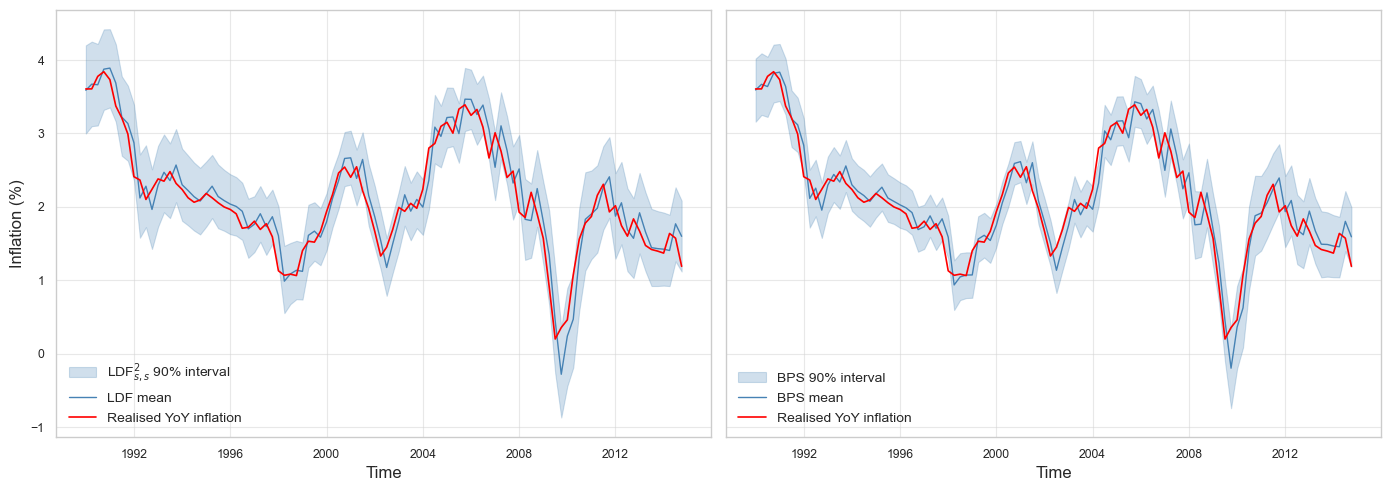

In [9]:
def pool_quantile(F, p, grid):
    return np.array([np.interp(p, F[t], grid) for t in range(F.shape[0])])

fig, axes = plt.subplots(1,2, figsize=(14, 5), sharex=True, sharey=True)
for ax, (name, P) in zip(axes, POOLS.items()):
    q05 = pool_quantile(P["cdfs"][0], 0.05, x_grid); q95 = pool_quantile(P["cdfs"][0], 0.95, x_grid)
    lab = rf"LDF$^2_{{s,s}}$ 90% interval" if name == "LDF" else "BPS 90% interval"
    ax.fill_between(dates, q05, q95, color="steelblue", alpha=0.25, label=lab)
    ax.plot(dates, P["mean"], color="steelblue", lw=1, label=f"{name} mean")
    ax.plot(dates, y_w, color="red", lw=1.2, label="Realised YoY inflation")
    ax.set_xlabel("Time", fontsize=12)
    ax.grid(alpha=0.5, which="major", c="lightgrey")
    ax.legend(fontsize=10, loc="lower left",frameon=False)
    print(f"{name}: empirical coverage of the 90% interval: {np.mean((y_w >= q05) & (y_w <= q95)):.1%}")
axes[0].set_ylabel("Inflation (%)", fontsize=12)
fig.tight_layout(); fig.savefig(OUT / "bps_vs_ldf_interval.png", dpi=600); plt.show()

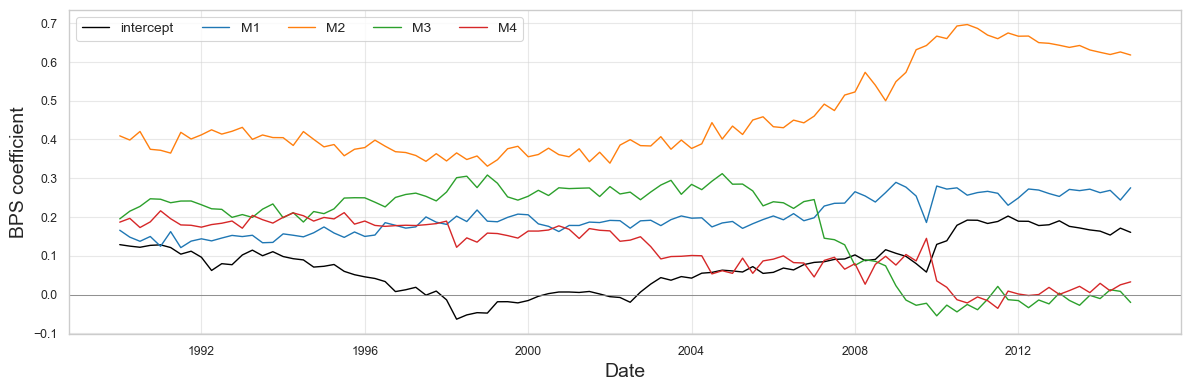

In [10]:
# BPS synthesis coefficients: posterior mean of theta_{t+1} at each origin
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dates, bps_out["a_k"][:, 0], color="black", lw=1, label="intercept")
for j, m in enumerate(models):
    ax.plot(dates, bps_out["a_k"][:, j + 1], lw=1, label=m)
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("Date", fontsize=14); ax.set_ylabel("BPS coefficient", fontsize=14)
ax.grid(alpha=0.5, which="major", c="lightgrey"); ax.legend(fontsize=10, ncol=5, loc="upper left")
fig.tight_layout(); fig.savefig(OUT / "bps_coefficients.png", dpi=300); plt.show()

## 4. Recalibration of both pools (settings of `inflation.ipynb`)

In [11]:
def recalibrate(P):
    common = dict(x=x_grid, y=y_w, pit_data=P["pits"], cdf_data=P["cdfs"],
                  discount_factors=P["label"], warmup=warmup, eval_start=eval_start, alpha=ALPHA)
    R = dict(
        rg=tvgas_pit_dma_new(K=K_RQS, static_baseline=True, static_refit_every=STATIC_REFIT, **common),
        rc=convolution_recal_pit_dma_new(K=K_RQS, refit_every=10, hidden_size=6, num_epochs=300,
                                         learning_rate=1e-3, seed=42, verbose=True, **common),
        bg=tvgas_pit_beta_dma_new(floor=1e-3, static_baseline=True, static_refit_every=STATIC_REFIT, **common),
        bc=convolution_recal_pit_beta_dma_new(floor=1e-3, refit_every=10, hidden_size=6, num_epochs=300,
                                              learning_rate=1e-3, seed=42, verbose=True, **common))
    # static maps as reports in the same format (tau_grid, log_likelihood = ll_static, v_transformed)
    R["rs"] = static_reports(R["rg"], "rqs", K=K_RQS)
    R["bs"] = static_reports(R["bg"], "beta")
    return R

RECAL = {name: recalibrate(P) for name, P in POOLS.items()}
index = 0          # one pool per method list (P = 1)

# every model, in table order: static, GAS, Con per family
MODELS = [("rs", "Static RQS"), ("rg", "RQS-GAS"), ("rc", "RQS-Con"),
          ("bs", "Static Beta"), ("bg", "Beta-GAS"), ("bc", "Beta-Con")]
STYLE = {"rs": ("#9467bd", ":"), "rg": ("#2ca02c", "-."), "rc": ("#1f77b4", "-"),
         "bs": ("#7f7f7f", ":"), "bg": ("#d62728", ":"), "bc": ("#ff7f0e", "--")}


def pits_of(R, k):
    """Recalibrated PITs on the scored window, for a method or a static map."""
    r = R[k][index]
    if "calibrated_pits" in r:
        return np.asarray(r["calibrated_pits"], float)
    return np.asarray(r["v_transformed"], float)[eval_start:]


Two-timescale GAS (aggregated)  v = tau_GAS(u)  |  base: 0.9
  weights: slow=0.32  identity=0.30  glacial=0.28   (eff. 3.38 of 5; mass on fast filters 0.10; alpha=0.95, memory~20)
  EVALUATION [0,100)  n=100
     log-score total    +0.729   per obs +0.0073 (SE 0.0264)   t=+0.26  p=0.796
     oracle ceiling +0.0414/obs  -> captured 18%
     best single filter 'glacial' +0.0059/obs; mixture +0.0013 vs it (no-harm floor, valid at alpha=1: -0.0161)
     static expanding map -0.1331/obs (KS 0.0756);  GAS - static +0.1403  t=+3.15  p=0.002
     90% interval  width 0.9521 -> 0.9199   coverage 0.960 -> 0.930   IS 1.0184 -> 1.0017 (t=+1.58)
     KS   0.1183 -> 0.0886   (null mean 0.0869)
     ECE  0.2400 -> 0.2200   CRPS 0.1378 -> 0.1371
     mean bias +0.0442 -> +0.0213
     PIT var by third  0.0367 0.0757 0.0867  ->  0.0530 0.0899 0.0885   (target 0.0833)

Composition  v = tau_GAS(tau_NN(u))  |  base: 0.9
  alpha=0.95 (memory~20), floor=0.001, step_norm=coord   eff. experts: raw bank 3.38, o

### Uniformity tests

In [12]:
TESTS = {}
for name, P in POOLS.items():
    TESTS[f"{name} raw"] = uniformity_test(P["pits"][:, eval_start:], P["label"])[1]
    for k, lab in MODELS:
        TESTS[f"{name} {lab}"] = uniformity_test(pits_of(RECAL[name], k)[None, :], P["label"])[1]
pd.concat(TESTS)

,,Model,Tests_Passed,KS_Test,AD_Test,Chi2_Test,DH_Test,LB_Test,Berkowitz_Test,Mean_Test,Variance_Test,Coverage_5%_Test,Coverage_95%_Test,Efficiency_Test,Probabilistic_Calibration,Complete_Calibration
LDF raw,0,δ = 0.9,5/10,PASS,FAIL,PASS,PASS,FAIL,FAIL,FAIL,FAIL,PASS,PASS,N/A,Rejected,Rejected
LDF Static RQS,0,δ = 0.9,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
LDF RQS-GAS,0,δ = 0.9,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
LDF RQS-Con,0,δ = 0.9,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
LDF Static Beta,0,δ = 0.9,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
LDF Beta-GAS,0,δ = 0.9,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
LDF Beta-Con,0,δ = 0.9,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
BPS raw,0,δ = 0.95,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
BPS Static RQS,0,δ = 0.95,8/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,FAIL,N/A,Not rejected,Rejected
BPS RQS-GAS,0,δ = 0.95,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected


In [13]:
def tests_passed_latex(tables, caption="Number of tests passed for each method",
                       label="tab:tests-passed"):
    """tables: {row label: test-result DataFrame}. Counts the rows marked PASS in each test column."""
    cols = [("KS_Test", "KS"), ("AD_Test", "AD"), ("Chi2_Test", r"$\chi^2$"),
            ("DH_Test", "DH"), ("LB_Test", "LB"), ("Berkowitz_Test", "Berkowitz")]
    lines = [r"\begin{table}[H]", r"\centering", r"\onehalfspacing", r"\small",
             r"\begin{tabular}{l " + "c " * len(cols) + "}", r"\toprule",
             " & " + " & ".join(h for _, h in cols) + r" \\", r"\midrule"]
    for name, df in tables.items():
        counts = [int(df[c].astype(str).str.strip().str.upper().eq("PASS").sum()) for c, _ in cols]
        lines.append(f"{name} & " + " & ".join(map(str, counts)) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", rf"\caption{{{caption}}}",
              rf"\label{{{label}}}", r"\end{table}"]
    print("\n".join(lines))

# one pool per row, so each entry is 1 (pass) or 0 (fail)
tests_passed_latex(TESTS, caption="Uniformity / independence tests passed: LDF vs BPS, before and after recalibration",
                   label="tab:tests-bps-ldf")

\begin{table}[H]
\centering
\onehalfspacing
\small
\begin{tabular}{l c c c c c c }
\toprule
 & KS & AD & $\chi^2$ & DH & LB & Berkowitz \\
\midrule
LDF raw & 1 & 0 & 1 & 1 & 0 & 0 \\
LDF Static RQS & 1 & 1 & 1 & 1 & 0 & 1 \\
LDF RQS-GAS & 1 & 1 & 1 & 1 & 0 & 1 \\
LDF RQS-Con & 1 & 1 & 1 & 1 & 0 & 1 \\
LDF Static Beta & 1 & 1 & 1 & 1 & 0 & 1 \\
LDF Beta-GAS & 1 & 1 & 1 & 1 & 0 & 1 \\
LDF Beta-Con & 1 & 1 & 1 & 1 & 0 & 1 \\
BPS raw & 1 & 1 & 1 & 1 & 0 & 1 \\
BPS Static RQS & 1 & 1 & 1 & 1 & 0 & 1 \\
BPS RQS-GAS & 1 & 1 & 1 & 1 & 0 & 1 \\
BPS RQS-Con & 1 & 1 & 1 & 1 & 0 & 1 \\
BPS Static Beta & 1 & 1 & 1 & 1 & 0 & 1 \\
BPS Beta-GAS & 1 & 1 & 1 & 1 & 0 & 1 \\
BPS Beta-Con & 1 & 1 & 1 & 1 & 0 & 1 \\
\bottomrule
\end{tabular}
\caption{Uniformity / independence tests passed: LDF vs BPS, before and after recalibration}
\label{tab:tests-bps-ldf}
\end{table}


### PIT ECDF (as in `inflation.ipynb`)

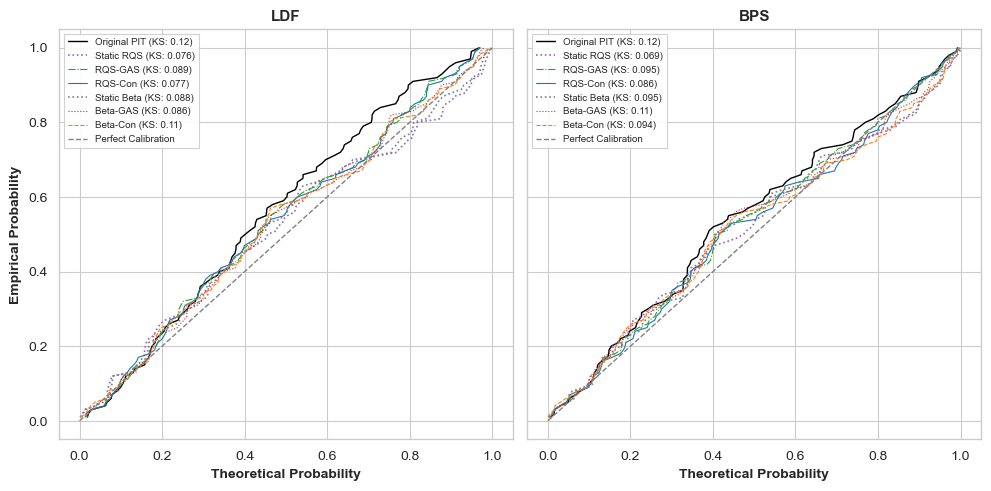

In [14]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for ax, (name, P) in zip(axes, POOLS.items()):
    R = RECAL[name]
    pit_example = P["pits"][index, warmup:]
    ecdf = np.arange(1, len(pit_example) + 1) / len(pit_example)
    ax.plot(np.sort(pit_example), ecdf, color="black", lw=1,
            label=f"Original PIT (KS: {R['rc'][index]['ks_before']:.2g})")
    for k, lab in MODELS:
        col, ls = STYLE[k]
        u = pits_of(R, k)
        ax.plot(np.sort(u), np.arange(1, len(u) + 1) / len(u), color=col, linestyle=ls,
                lw=1.2 if k in ("rs", "bs") else 0.8,
                label=f"{lab} (KS: {stats.kstest(u, 'uniform').statistic:.2g})")
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Perfect Calibration", lw=1)
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_xlabel("Theoretical Probability", fontsize=10, fontweight="bold")
    ax.tick_params(axis="both", labelsize=10)
    ax.legend(fontsize=7, loc="upper left", frameon=True, framealpha=0.9, edgecolor="0.8", fancybox=False)
axes[0].set_ylabel("Empirical Probability", fontsize=10, fontweight="bold")
plt.tight_layout(); fig.savefig(OUT / "bps_vs_ldf_ecdf.png", dpi=300); plt.show()

### Cumulative log-score gain over the raw pool

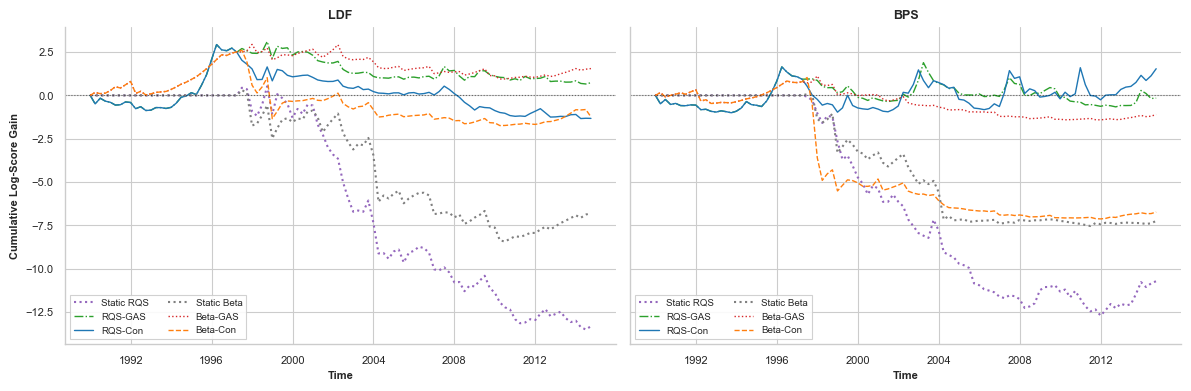

mean log-score gain  t (HAC DM)
LDF Static RQS               -0.1331     -2.7780
    RQS-GAS                   0.0073      0.2591
    RQS-Con                  -0.0133     -0.4215
    Static Beta              -0.0678     -1.7405
    Beta-GAS                  0.0154      0.8208
    Beta-Con                 -0.0124     -0.3926
BPS Static RQS               -0.1071     -2.4489
    RQS-GAS                  -0.0016     -0.0543
    RQS-Con                   0.0153      0.3916
    Static Beta              -0.0724     -2.3573
    Beta-GAS                 -0.0110     -0.8090
    Beta-Con                 -0.0672     -1.2928

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, POOLS):
    R = RECAL[name]
    for k, lab in MODELS:
        col, ls = STYLE[k]
        ax.plot(dates[warmup:], np.cumsum(np.asarray(R[k][index]["log_likelihood"])[warmup:]),
                label=lab, color=col, linestyle=ls, linewidth=1.5 if k in ("rs", "bs") else 1)
    ax.axhline(y=0, color="black", linestyle=":", linewidth=0.8, alpha=0.5)
    ax.set_title(name, fontsize=9, fontweight="bold")
    ax.set_xlabel("Time", fontsize=8, fontweight="bold"); ax.tick_params(axis="both", labelsize=8)
    ax.legend(fontsize=7, loc="lower left", ncol=2, frameon=True, framealpha=0.9, edgecolor="0.8", fancybox=False)
axes[0].set_ylabel("Cumulative Log-Score Gain", fontsize=8, fontweight="bold")
sns.despine(trim=False); plt.tight_layout(); fig.savefig(OUT / "bps_vs_ldf_cum_gain.png", dpi=300); plt.show()


def dm_t(d):
    d = np.asarray(d, float)
    return dm_test(d, hac_lag=_hac_lag(len(d)))[2]


GAINS = {}
for name in POOLS:
    for k, lab in MODELS:
        d = np.asarray(RECAL[name][k][index]["log_likelihood"], float)[eval_start:]
        GAINS[(name, lab)] = {"mean log-score gain": d.mean(), "t (HAC DM)": dm_t(d)}
pd.DataFrame(GAINS).T.round(4)

### Raw vs recalibrated 90% intervals

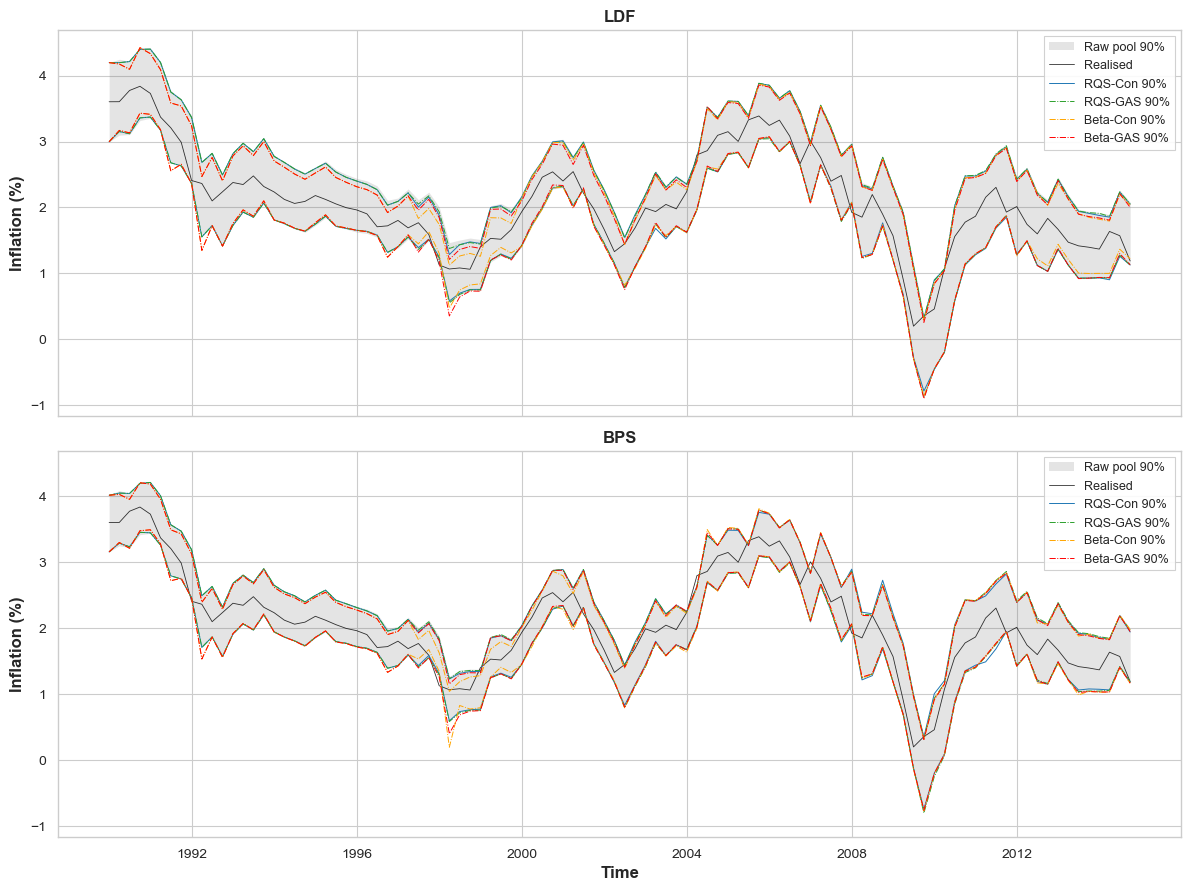

--- LDF ---
RQS-Con          coverage  93.0% (raw  96.0%)   mean width 0.9153 = 96.1% of raw
RQS-GAS          coverage  93.0% (raw  96.0%)   mean width 0.9199 = 96.6% of raw
Beta-Con         coverage  89.0% (raw  96.0%)   mean width 0.8429 = 88.5% of raw
Beta-GAS         coverage  91.0% (raw  96.0%)   mean width 0.8673 = 91.1% of raw
Static RQS       coverage  87.0%                mean width 0.8015 = 84.2% of raw
Static Beta      coverage  86.0%                mean width 0.7962 = 83.6% of raw
--- BPS ---
RQS-Con          coverage  89.0% (raw  90.0%)   mean width 0.7385 = 98.5% of raw
RQS-GAS          coverage  88.0% (raw  90.0%)   mean width 0.7442 = 99.3% of raw
Beta-Con         coverage  84.0% (raw  90.0%)   mean width 0.7104 = 94.8% of raw
Beta-GAS         coverage  88.0% (raw  90.0%)   mean width 0.7236 = 96.5% of raw
Static RQS       coverage  84.0%                mean width 0.7191 = 95.9% of raw
Static Beta      coverage  85.0%                mean width 0.7209 = 96.2% of raw


In [19]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True, sharey=True)
for ax, name in zip(axes, POOLS):
    R = RECAL[name]; es = R["rc"][index]["eval_start"]; sl = slice(es, len(dates))
    ax.fill_between(dates[sl], np.asarray(R["rc"][index]["y_raw_q05"])[sl], np.asarray(R["rc"][index]["y_raw_q95"])[sl],
                    color="#4d4d4d", alpha=0.15, linewidth=0, label="Raw pool 90%")
    ax.plot(dates[sl], y_w[sl], color="black", linewidth=0.6, alpha=0.8, label="Realised")
    for k, lab, col, ls in [("rc", "RQS-Con", "#1f77b4", "-"), ("rg", "RQS-GAS", "#2ca02c", "-."),
                            ("bc", "Beta-Con", "orange", "-."), ("bg", "Beta-GAS", "red", "-.")]:
        ax.plot(dates[sl], np.asarray(R[k][index]["y_calibrated_q05"])[sl], color=col, linestyle=ls, linewidth=0.7,
                label=f"{lab} 90%")
        ax.plot(dates[sl], np.asarray(R[k][index]["y_calibrated_q95"])[sl], color=col, linestyle=ls, linewidth=0.7)
    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.legend(fontsize=9, loc="upper right", frameon=True, framealpha=0.9, edgecolor="0.8", fancybox=False)
    ax.set_ylabel("Inflation (%)", fontsize=12, fontweight="bold"); ax.tick_params(axis="both", labelsize=10)
axes[-1].set_xlabel("Time", fontsize=12, fontweight="bold")
fig.tight_layout(); fig.savefig(OUT / "bps_vs_ldf_intervals_recal.png", dpi=300); plt.show()


def interval_summary(d, y, sl, name):
    lo, hi = np.asarray(d[index]["y_calibrated_q05"])[sl], np.asarray(d[index]["y_calibrated_q95"])[sl]
    lo_r, hi_r = np.asarray(d[index]["y_raw_q05"])[sl], np.asarray(d[index]["y_raw_q95"])[sl]
    yy = np.asarray(y)[sl]
    cov = float(np.mean((yy >= lo) & (yy <= hi)))
    cov_raw = float(np.mean((yy >= lo_r) & (yy <= hi_r)))
    w, w_raw = float(np.mean(hi - lo)), float(np.mean(hi_r - lo_r))
    print(f"{name:16s} coverage {cov:6.1%} (raw {cov_raw:6.1%})   "
          f"mean width {w:.4f} = {w / w_raw:5.1%} of raw")


def static_interval_summary(rep, cdfs, y, sl, name, raw_w):
    q = np.array([_pit_quantiles(cdfs[t], x_grid, rep["tau_grid"][t], _IVL_PROBS) for t in range(len(y))])
    yy = np.asarray(y)[sl]
    cov = float(np.mean((yy >= q[sl, 0]) & (yy <= q[sl, 1])))
    w = float(np.mean(q[sl, 1] - q[sl, 0]))
    print(f"{name:16s} coverage {cov:6.1%}                mean width {w:.4f} = {w / raw_w:5.1%} of raw")


for pool in POOLS:
    R = RECAL[pool]; sl = slice(R["rc"][index]["eval_start"], len(dates))
    raw_w = float(np.mean(np.asarray(R["rc"][index]["y_raw_q95"])[sl] - np.asarray(R["rc"][index]["y_raw_q05"])[sl]))
    print(f"--- {pool} ---")
    for nm, k in [("RQS-Con", "rc"), ("RQS-GAS", "rg"), ("Beta-Con", "bc"), ("Beta-GAS", "bg")]:
        interval_summary(R[k], y_w, sl, nm)
    for nm, k in [("Static RQS", "rs"), ("Static Beta", "bs")]:
        static_interval_summary(R[k][index], POOLS[pool]["cdfs"][0], y_w, sl, nm, raw_w)

## 5. Localized metrics

In [20]:
LOC = {}
for name, P in POOLS.items():
    R = RECAL[name]
    print(f"\n==================== {name} ====================")
    LOC[name] = evaluate_localized(
        x=x_grid, y=y_w, pit_data=P["pits"], cdf_data=P["cdfs"],
        methods={"GAS spline": R["rg"], "CONV spline": R["rc"], "GAS beta": R["bg"], "CONV beta": R["bc"],
                 "Static spline": R["rs"], "Static beta": R["bs"]},
        discount_factor=P["label"][0], eval_start=eval_start, min_events=15, n_blocks=2,
        threshold_window="auto", target=2.0, radii=(1.0,))


==================== LDF ====================

LOCALIZED EVALUATION   base pool = pit_data row 0   discount factor 0.9
  window [0,100)   n=100   offset 0   max |PIT_grid - PIT_stored| = 0.00e+00
  regions (rolling 48 thresholds, n=100, min_events=15): tails q=0.2, 2 blocks
    realised counts -> left tail  q=0.2:43, right tail q=0.8:16, left tail  q=0.25:49, right tail q=0.75:20, block 1/2:68, block 2/2:32, band 2+-1:80, off band 2+-1:20

INPUT CHECKS
[discount factor 0.9   window [0,100)   n=100]
                               value
pool row                           0
offset                             0
window                       [0,100)
n                                100
max |PIT_grid - PIT_stored|   0.0000
KS PIT stored                 0.1183
KS PIT grid                   0.1183
grid mass                     1.0000
obs outside grid              0.0000

MASTER TABLE -- levels  (delta = gain over the raw pool, POSITIVE ALWAYS MEANS BETTER; HAC t-stat stars)
[discount factor 0.

### Scorecard (all scores, static maps included)

In [28]:
Path("tables").mkdir(parents=True, exist_ok=True)
d = sr.DELTAS.index(0.9)
for name in POOLS:
    entry = {"inflation": {"group": "", "localized": {}}}
    sr.add_localized(entry, "inflation", LOC[name])
    # stored under the pool's discount factor; the scorecard reads the slot of DELTAS[d]
    entry["inflation"]["localized"] = {round(0.9, 6): next(iter(entry["inflation"]["localized"].values()))}
    tex = sr.scorecard_latex(entry, d, caption=(
        rf"US inflation, raw {name} on the BPS window ({dates.iloc[eval_start]:%Y}--{dates.iloc[-1]:%Y}). "
        r"KS: Kolmogorov--Smirnov distance of the PIT from uniform ($^\dagger$ rejects at 5\%). Raw pool: "
        r"level of each score; method columns: gain over the raw pool, positive is better. Stars: HAC "
        r"Giacomini--White test at 10/5/1\%. Static RQS, Static Beta: expanding-window static maps. Best in bold."))
    tex = tex.replace("inflation & KS", f"{name} & KS").replace(r"\label{tab:sim_scorecard}",
                                                                rf"\label{{tab:infl-scores-{name.lower()}}}")
    print(tex); open(f"tables/inflation_scores_{name.lower()}.tex", "w").write(tex)

\begin{table}[H]\centering\small
\begin{tabular}{llccccccc}\toprule
Scenario & Metric & Raw pool & Static RQS & RQS-GAS & RQS-Con & Static Beta & Beta-GAS & Beta-Con \\ \midrule
LDF & KS & $0.118$ & $\mathbf{0.076}$ & $0.089$ & $0.077$ & $0.088$ & $0.086$ & $0.108$ \\
 & LogS & $-0.0301$ & $-0.1331^{***}$ & $+0.0073$ & $-0.0133$ & $-0.0678^{*}$ & $\mathbf{+0.0154}$ & $-0.0124$ \\
 & CRPS & $0.1401$ & $-0.0035$ & $+0.0004$ & $\mathbf{+0.0007}$ & $-0.0027$ & $-0.0012$ & $-0.0019$ \\
 & IS$_{90}$ & $1.0184$ & $-0.0737$ & $+0.0170$ & $+0.0120$ & $-0.0918$ & $\mathbf{+0.0317}$ & $+0.0060$ \\
 & IS$_{95}$ & $1.1734$ & $-0.0365$ & $+0.0201^{***}$ & $+0.0088$ & $-0.1071$ & $\mathbf{+0.0891^{***}}$ & $+0.0255$ \\
 & CSL$_{L}$ & $-0.0831$ & $-0.0579^{*}$ & $\mathbf{+0.0163}$ & $-0.0027$ & $-0.0444$ & $+0.0042$ & $-0.0274$ \\
 & CSL$_{R}$ & $-0.1114$ & $-0.0279$ & $-0.0055$ & $-0.0040$ & $-0.0236$ & $+0.0000$ & $\mathbf{+0.0034}$ \\
\bottomrule\end{tabular}
\caption{US inflation, raw LDF on the B

In [22]:
pickle.dump({"recal": RECAL, "pools": POOLS, "bps_out": bps_out, "idx": idx, "loc": LOC},
            open("results/bps_vs_ldf_recal.pkl", "wb"))